# Stats for AI, Bloque 2
## ¿Qué determina el apalancamiento financiero de una empresa?

**Nombre:** Oswaldo Isaias Hernández Santes
**Matrícula:** A01199004

**Cálculo de la razón asignada:**
- Suma de dígitos: 0 + 1 + 1 + 9 + 9 + 0 + 0 + 4 = 24
- 24 mod 3 = 0
- 0 + 1 = **1** → **Razón #1: Apalancamiento financiero**

$$Y = \frac{shortdebt + longdebt}{totalassets}$$

**Pregunta de negocio:** ¿Qué características de una empresa explican cuánta deuda financiera utiliza para financiar sus activos?

## Parte 1. Preparación de datos y entendimiento de la razón financiera

In [1]:
# Librería para manejar tablas de datos (DataFrames)
import pandas as pd

# Librería para cálculos numéricos y álgebra matricial
import numpy as np

# Librería para hacer gráficas
import matplotlib.pyplot as plt

# Muestra hasta 30 columnas al imprimir un DataFrame (el dataset tiene 27)
pd.set_option("display.max_columns", 30)

# Amplía el ancho de impresión para que las tablas no se corten
pd.set_option("display.width", 150)

In [2]:
# Lee los datos financieros; utf-8-sig elimina el BOM al inicio del archivo
findata = pd.read_csv("data/usfindata.csv", encoding="utf-8-sig")

# Lee el catálogo de empresas con la misma codificación
firms = pd.read_csv("data/usfirms.csv", encoding="utf-8-sig")

# Muestra cuántos renglones y columnas tiene cada dataset
print("usfindata:", findata.shape)
print("usfirms:", firms.shape)

# Muestra los nombres de las columnas para verificar que la primera sea 'ticker'
print(findata.columns.tolist())
print(firms.columns.tolist())

usfindata: (37422, 27)
usfirms: (7187, 7)
['ticker', 'year', 'status', 'naics1', 'revenue', 'cogs', 'sgae', 'depreciation', 'otherincome', 'extraordinaryitems', 'finexp', 'incometax', 'cashflowoper', 'totalassets', 'currentassets', 'accountsreceivables', 'inventory', 'totalliabilities', 'currentliabilities', 'accountspayable', 'shortdebt', 'longdebt', 'retainedearnings', 'adjprice', 'originalprice', 'sharesoutstanding', 'fixedassets']
['ticker', 'Nombre', 'status', 'partind', 'naics1', 'naics2', 'SectorEconomatica']


### 1a. Filtro de 2024 y unión de datasets

In [3]:
# Conserva solo los renglones cuyo año fiscal es 2024; .copy() crea una tabla independiente
findata_2024 = findata[findata["year"] == 2024].copy()

# Muestra cuántos renglones (empresas) quedaron en 2024
print("Renglones en 2024:", findata_2024.shape[0])

Renglones en 2024: 3740


Podemos ver que el dataset findata contiene 3,740 empresas con datos del 2024.

In [4]:
# Marca como verdadero cada ticker que ya apareció antes y suma cuántos hay en los datos de 2024
duplicados_findata = findata_2024["ticker"].duplicated().sum()

# Hace lo mismo con el catálogo de empresas
duplicados_firms = firms["ticker"].duplicated().sum()

print("Tickers duplicados en findata 2024:", duplicados_findata)
print("Tickers duplicados en firms:", duplicados_firms)

Tickers duplicados en findata 2024: 0
Tickers duplicados en firms: 0


Podemos ver que no encontramos duplicados en ninguno de los datasets.

In [5]:
# Une los datos de 2024 con el catálogo usando ticker como llave (equivalente a un LEFT JOIN de SQL)
# how="left" conserva todas las empresas de 2024 aunque no estén en el catálogo
# indicator=True agrega la columna _merge, que dice si cada empresa encontró pareja
# suffixes deja sin cambio las columnas de findata y agrega "_catalogo" a las repetidas del catálogo
datos = pd.merge(
    findata_2024,
    firms,
    on="ticker",
    how="left",
    indicator=True,
    suffixes=("", "_catalogo")
)

# Muestra cuántas empresas encontraron pareja (both) y cuántas no (left_only)
print(datos["_merge"].value_counts())

# Cuenta cuántas empresas del catálogo no tienen datos en 2024; ~ significa "no"
sin_datos_2024 = (~firms["ticker"].isin(findata_2024["ticker"])).sum()

print("Empresas del catálogo sin datos en 2024:", sin_datos_2024)

_merge
both          3740
left_only        0
right_only       0
Name: count, dtype: int64
Empresas del catálogo sin datos en 2024: 3447


Después de hacer el merge (la combinación) de ambos datasets dependiendo de su ticker podemos observar que ninguna empresa se quedó sin nombre o sector, otro dato interesante es que hay 3,447 empresas que no tienen datos del 2024, esto puede deberse a que algunas dejaron de cotizar en la bolsa para ese año.

In [6]:
# Se queda solo con las empresas que sí encontraron pareja en el catálogo
con_pareja = datos[datos["_merge"] == "both"]

# Cuenta en cuántas empresas el sector de findata es distinto al del catálogo
# fillna("") cambia los vacíos por texto vacío, porque dos vacíos se consideran distintos al compararlos
diferencias_naics1 = (con_pareja["naics1"].fillna("") != con_pareja["naics1_catalogo"].fillna("")).sum()

# Hace lo mismo con el estatus en bolsa
diferencias_status = (con_pareja["status"].fillna("") != con_pareja["status_catalogo"].fillna("")).sum()

print("Empresas con sector distinto entre archivos:", diferencias_naics1)
print("Empresas con estatus distinto entre archivos:", diferencias_status)

# Muestra cada sector y cuántas empresas tiene, incluyendo las que no tienen sector (NaN)
print(datos["naics1"].value_counts(dropna=False))

Empresas con sector distinto entre archivos: 0
Empresas con estatus distinto entre archivos: 1
naics1
Manufacturing                                                               1559
Finance and Insurance                                                        803
Information                                                                  253
Professional, Scientific, and Technical Services                             169
Retail Trade                                                                 134
Mining, Quarrying, and Oil and Gas Extraction                                124
Administrative and Support and Waste Management and Remediation Services     108
Transportation and Warehousing                                                89
Utilities                                                                     86
Wholesale Trade                                                               80
Real Estate and Rental and Leasing                                            75
Health 

Podemos ver que para cada empresa hay un sector o estatus específico, al combinar estos datasets lo que no queremos es tener diferentes para la misma empresa (que sean consistentes), vemos que no hay algún error con los sectores asignados por empresa entre ambos datasets, en cambio para el estatus sí es distinto, necesitamos revisar por qué, lo haremos la celda siguiente.

También podemos observar cuántas empresas se dedican a qué sector, por ejemplo podemos ver que el sector más grande es de manufactura mientras que el más pequeño es el de servicios educativos.

In [7]:
# Selecciona la empresa cuyo estatus no coincide; .loc[filas, columnas] elige renglones y columnas a mostrar
print(con_pareja.loc[
    con_pareja["status"].fillna("") != con_pareja["status_catalogo"].fillna(""),
    ["ticker", "Nombre", "status", "status_catalogo"]
])

# Cuenta el estatus en bolsa de las empresas del catálogo que no tienen datos en 2024
print(firms.loc[~firms["ticker"].isin(findata_2024["ticker"]), "status"].value_counts(dropna=False))

     ticker              Nombre  status status_catalogo
2249    MSN  Emerson Radio Corp  active       cancelled
status
cancelled    2240
active       1207
Name: count, dtype: int64


Como podemos observar tenemos esta empresa con ticker MSN que tiene 2 estatus diferentes, por esa razón es que anteriormente vimos que habia una empresa que tuvo diferentes estatus, pero esto no afecta al modelo ya que no usamos el estatus como variable.

### 1b. Muestra de análisis (embudo)

Antes de filtrar nuestros datos necesitamos saber si los datos están limpios, por lo tanto buscamos valores nulos, ceros o negativos.

In [8]:
# Excluye el sector financiero; != significa "distinto de"
no_financieras = datos[datos["naics1"] != "Finance and Insurance"].copy()

# Muestra cuántas empresas quedan sin el sector financiero
print("Empresas no financieras:", no_financieras.shape[0])

# Lista de columnas necesarias para calcular Y y las 5 X
columnas_necesarias = ["totalassets", "shortdebt", "longdebt", "fixedassets", "revenue",
                       "cogs", "sgae", "depreciation", "originalprice", "sharesoutstanding"]

# Arma una tabla con faltantes, ceros y negativos por columna
# .isna() marca los vacíos, == 0 los ceros y < 0 los negativos; .sum() cuenta los verdaderos
diagnostico = pd.DataFrame({
    "faltantes": no_financieras[columnas_necesarias].isna().sum(),
    "ceros": (no_financieras[columnas_necesarias] == 0).sum(),
    "negativos": (no_financieras[columnas_necesarias] < 0).sum()
})

print(diagnostico)

# Cuenta empresas a las que les faltan las dos deudas al mismo tiempo; & significa "y"
ambas_faltantes = (no_financieras["shortdebt"].isna() & no_financieras["longdebt"].isna()).sum()

# Cuenta empresas a las que les falta solo una de las dos deudas
# != entre dos columnas de verdadero/falso es verdadero cuando una falta y la otra no
una_faltante = (no_financieras["shortdebt"].isna() != no_financieras["longdebt"].isna()).sum()

print("Empresas sin ninguna de las dos deudas:", ambas_faltantes)
print("Empresas con solo una deuda faltante:", una_faltante)

Empresas no financieras: 2937
                   faltantes  ceros  negativos
totalassets                0      3          0
shortdebt                  0   1484          0
longdebt                   0   1491          0
fixedassets                0    613          0
revenue                    0      0          1
cogs                       0    899          1
sgae                       0      0         76
depreciation               0    249          1
originalprice             74      0          0
sharesoutstanding        163      0          0
Empresas sin ninguna de las dos deudas: 0
Empresas con solo una deuda faltante: 0


La tabla recopiló una buena información, primero encontramos que tenemos 2,937 empresas no financieras, para todas las empresas tenemos valores en sus deudas así que no habrá problema en calcular su Y.

Un dato importante es que hay demasiados ceros, en deuda (aprox 1,490), costo de ventas (899), activos fijos (613), y depreciación (249), para la feature de deuda es válido porque pueden existir empresas que no piden prestado y su Y es de cero.

Algo que debemos notar es que la mayoría del dataset no tiene datos vacíos (a excepción del precio y las acciones), esto nos puede decir que en algunos casos puede que los ceros son datos no reportados en vez de ser vacíos, por ejemplo es raro que 613 empresas no tengan algún activo fijo y no podemos saber si todos estos son ceros reales. Frank y Goyal(2009, nota 15) también tratan algunos datos no reportados como valores en cero, así que puede ser una práctica adecuada siguiendo este ejemplo.

En totalassets (activos totales) tenemos tres ceros que debemos descartar ya que no podemos dividir entre cero.

Donde tenemos valores faltantes es en el precio y las acciones, sin estos datos no podemos calcular las oportunidades de crecimiento, entonces tendremos que descartar estos datos.

En cuanto a los valores negativos podemos ver que la venta de una empresa es negativa lo cual es raro, al igual que en costo de ventas, gastos de ventas (generales o de administracdion) y en la depreciación, estos pueden ser errores de captura y esto importa ya que mi rentabilidad es ventas - costo - gastos, a continuación investigaré más acerca de estos valores anormales.

In [9]:
# Selecciona empresas con algún ingreso o gasto negativo; | significa "o"
negativos = no_financieras[(no_financieras["revenue"] < 0) | (no_financieras["cogs"] < 0) |
                           (no_financieras["sgae"] < 0) | (no_financieras["depreciation"] < 0)]

print("Empresas con algún valor negativo:", negativos.shape[0])

# Muestra 15 de ellas, empezando por la de gasto de venta y administración más negativo
print(negativos[["ticker", "Nombre", "naics1", "revenue", "cogs", "sgae", "depreciation", "totalassets"]]
      .sort_values("sgae").head(15))

# Cuenta empresas sin precio o sin número de acciones (a una misma empresa le pueden faltar ambos)
sin_mercado = (no_financieras["originalprice"].isna() | no_financieras["sharesoutstanding"].isna()).sum()

print("Empresas sin precio o sin acciones:", sin_mercado)

# Cuenta empresas con las dos deudas en cero, que tendrán Y = 0
sin_deuda = ((no_financieras["shortdebt"] == 0) & (no_financieras["longdebt"] == 0)).sum()

print("Empresas sin deuda financiera:", sin_deuda)

Empresas con algún valor negativo: 78
     ticker                           Nombre                                         naics1     revenue        cogs       sgae  depreciation  \
372    BALL                        Ball Corp                                  Manufacturing     68000.0         0.0 -4690000.0      611000.0   
2876   ROIV            Roivant Sciences Ltd.                                  Manufacturing    124795.0         0.0 -4309258.0       22036.0   
2268     MU           Micron Technology, Inc                                  Manufacturing  25111000.0  19498000.0 -3989000.0     7780000.0   
228     APD  Air Products And Chemicals, Inc                                  Manufacturing  12100600.0   8168700.0 -2584900.0     1451100.0   
1303    FLR                       Fluor Corp                                   Construction  16315000.0  15741000.0 -2324000.0       73000.0   
82      AES                         AES Corp                                      Utilities  12278

Con esta tabla enocntramos que 78 empresas tienen un valor negativo, por ejemplo Ball Corp tuvo venta de $68 millones, sus gastos de venta y administración fueron de $4,690 millones y sus activos son de $17,628 millones, no tiene mucho sentido que una empresa con casi $18,000 millones en activos solo tenga $68 millones de venta. Si calculamos su rentabilidad tenemos los siguiente

(68,000 − 0 − (−4,690,000)) / 17,628,000 = 4,758,000 / 17,628,000 ≈ 0.27

Según la fórmula y el resultado nos dice que la empresa gana 27 centavos por peso de activos, pero ese "ingreso" viene de un gasto negativo y no de su operación, por motivo de que esto es anormal y nosotros solo calculamos esta X a partir de utilidad de una operación normal excluiremos estas empresas con gastos negativos.

En un histograma veremos que aproximadamente el 45% de las empresas no cuentan con deuda financiera (1309) es decir, una Y = 0.

Ahora continuamos con el embudo.

In [10]:
def aplicar_filtro(tabla, condicion_conservar, descripcion, embudo):
    '''
    Aplica un filtro a la tabla y registra el resultado en el embudo.

    tabla: DataFrame antes de aplicar el filtro.
    condicion_conservar: serie de verdadero/falso; verdadero significa que la empresa se queda.
    descripcion: texto que explica por qué se aplica el filtro.
    embudo: lista donde se guarda el registro de cada paso.

    Regresa la tabla con solo las empresas que cumplen la condición.
    '''

    # Cuenta las empresas antes de aplicar el filtro
    antes = tabla.shape[0]

    # Conserva solo las empresas que cumplen la condición
    tabla_filtrada = tabla[condicion_conservar].copy()

    # Cuenta las empresas que quedaron después del filtro
    despues = tabla_filtrada.shape[0]

    # Guarda el paso en el embudo: qué filtro fue, cuántas se eliminaron y cuántas quedan
    embudo.append({"Filtro": descripcion, "Eliminadas": antes - despues, "Restantes": despues})

    return tabla_filtrada


# Inicia el embudo con el total de empresas después del merge
embudo = [{"Filtro": "Empresas con datos en 2024 (después del merge)", "Eliminadas": 0, "Restantes": datos.shape[0]}]

# Filtro 1: excluye el sector financiero
muestra = aplicar_filtro(datos, datos["naics1"] != "Finance and Insurance",
                         "Excluir sector Finance and Insurance", embudo)

# Filtro 2: conserva solo empresas con activos totales mayores a cero
muestra = aplicar_filtro(muestra, muestra["totalassets"] > 0,
                         "Excluir activos totales ≤ 0 (no se puede dividir entre cero)", embudo)

# Filtro 3: conserva solo empresas con precio y número de acciones mayores a cero
muestra = aplicar_filtro(muestra, (muestra["originalprice"] > 0) & (muestra["sharesoutstanding"] > 0),
                         "Excluir sin precio o sin número de acciones (no se puede calcular X4)", embudo)

# Filtro 4: conserva solo empresas sin ingresos ni gastos negativos
muestra = aplicar_filtro(muestra, (muestra["revenue"] >= 0) & (muestra["cogs"] >= 0) &
                         (muestra["sgae"] >= 0) & (muestra["depreciation"] >= 0),
                         "Excluir ingresos o gastos negativos (inconsistentes contablemente)", embudo)

# Convierte la lista del embudo en una tabla y la muestra
tabla_embudo = pd.DataFrame(embudo)
tabla_embudo

,Filtro,Eliminadas,Restantes
0,Empresas con datos en 2024 (después del merge),0,3740
1,Excluir sector Finance and Insurance,803,2937
2,Excluir activos totales ≤ 0 (no se puede divid...,3,2934
3,Excluir sin precio o sin número de acciones (n...,225,2709
4,Excluir ingresos o gastos negativos (inconsist...,72,2637


Embudo de la muestra de análisis

Partimos de 3740 empresas con datos en 2024 y terminamos con 2637 empresas.

1. Se excluyeron 803 empresas del sector Finance and Insurance porque la forma en que manejan sus deudas son distintas, para un banco la deuda es su “materia prima” que son los depósitos y su apalancamiento depende de regulación y seguros de depósito, también en las instrucciones se pide excluirlas.
2. Se excluyeron 3 empresas con activos totales iguales a cero porque al calcular X y Y variable no se puede dividir entre 0.
3. Se excluyeron 225 empresas sin precio o sin número de acciones porque son valores faltantes que no podemos imputar y para calcular las oportunidades de crecimiento son fundamentales tenerlas.
4. Se excluyeron 72 empresas con ingresos o gastos negativos porque queremos calcular la rentabilidad con utilidad que no tenga datos anormales.

En total se eliminó aproximadamente el 10% de las empresas no financieras por problemas de datos.

### 1c. Cálculo de Y y variables X

In [11]:
# Y: deuda financiera (corto + largo plazo) entre activos totales
muestra["apalancamiento_y"] = (muestra["shortdebt"] + muestra["longdebt"]) / muestra["totalassets"]

# X1: activos fijos entre activos totales
muestra["tangibilidad_x1"] = muestra["fixedassets"] / muestra["totalassets"]

# X2: EBITDA (ventas - costo de ventas - gastos de operación) entre activos totales
muestra["rentabilidad_x2"] = (muestra["revenue"] - muestra["cogs"] - muestra["sgae"]) / muestra["totalassets"]

# X3: logaritmo natural de los activos totales; np.log calcula el logaritmo natural (ln)
muestra["tamano_x3"] = np.log(muestra["totalassets"])

# X4: valor de mercado (precio por número de acciones) entre activos totales
muestra["crecimiento_x4"] = (muestra["originalprice"] * muestra["sharesoutstanding"]) / muestra["totalassets"]

# X5: depreciación entre activos totales
muestra["depreciacion_x5"] = muestra["depreciation"] / muestra["totalassets"]

# Lista con los nombres de Y y las X para reutilizarla en los siguientes incisos
variables_modelo = ["apalancamiento_y", "tangibilidad_x1", "rentabilidad_x2",
                    "tamano_x3", "crecimiento_x4", "depreciacion_x5"]

# Revisa que ninguna variable nueva tenga valores vacíos
print("Faltantes por variable:")
print(muestra[variables_modelo].isna().sum())

# Revisa que ninguna variable tenga valores infinitos (resultado de dividir entre cero)
print("Infinitos por variable:")
print(np.isinf(muestra[variables_modelo]).sum())

# Muestra las primeras 5 empresas con sus variables para verificar que los cálculos se ven razonables
muestra[["ticker", "Nombre"] + variables_modelo].head()

Faltantes por variable:
apalancamiento_y    0
tangibilidad_x1     0
rentabilidad_x2     0
tamano_x3           0
crecimiento_x4      0
depreciacion_x5     0
dtype: int64
Infinitos por variable:
apalancamiento_y    0
tangibilidad_x1     0
rentabilidad_x2     0
tamano_x3           0
crecimiento_x4      0
depreciacion_x5     0
dtype: int64


,ticker,Nombre,apalancamiento_y,tangibilidad_x1,rentabilidad_x2,tamano_x3,crecimiento_x4,depreciacion_x5
0,A,"Agilent Technologies, Inc",0.286173,0.150093,0.154060,16.287501,3.234242,0.021695
1,AA,Alcoa Corp,0.180958,0.454280,0.079849,16.459129,0.479428,0.045648
2,AAL,American Airlines Group Inc,0.493275,0.000000,0.081058,17.939139,0.185510,0.031174
5,AAOI,"Applied Optoelectronics, Inc",0.040893,0.400772,-0.090278,13.212263,3.328189,0.037747
6,AAON,"Aaon, Inc",0.013614,0.434259,0.228846,13.976978,8.154511,0.053381


Con los resultados tomaremos de ejemplo a la empresa con ticker "A", su apalancamiento es de aprox 0.28 equivalente a 28% esto quiere decir que el 28% de lo que tiene lo ha financiado con deuda financiera (préstamos y bonos), un 15% de sus activos son activos físicos (tangibles), sus operaciones generan 15.4 centavos por dolar de activos (rentabilidad), su tamaño está medido en el logaritmo natural de sus activos en miles de dólares que es aprox 16.2 y equivale a aprox 11,800 millones de activos, tiene oportunidad de crecimiento de 3, es decir que el mercado valora en 3 veces de lo que tiene registrado en libros, finalmente su depreciación es de aprox 2.2% es decir los gastos que hacen que ahorre impuestos la empresa o dicho de otra forma el desgaste contable de los activos que al ser un gasto reduce los impuestos.

Un dato importante que encontramos es que la tangibilidad de AAL es de 0, esta variable nos dice qué proporción de activos de la empresa son tangibles, como es una empresa de aerolíneas no tiene sentido que la tangibilidad sea de 0, ya sea por error de captura, por falta de reporte, entre otras posibles causas. Más adelante veremos cómo se comporta el modelo al usar estas empresas con ceros y sin usar estas empresas.

### 1d. Estadística descriptiva

In [12]:
# Calcula conteo, media, desviación estándar, mínimo, percentiles y máximo de cada variable
# .T voltea la tabla para que cada variable quede en un renglón
descriptiva = muestra[variables_modelo].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

# Redondea a 4 decimales y muestra la tabla
descriptiva.round(4)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
apalancamiento_y,2637.0,0.1887,0.2825,0.0000,0.0000,0.0000,0.0000,0.0473,0.3131,0.6780,1.1840,3.3681
tangibilidad_x1,2637.0,0.1255,0.1868,0.0000,0.0000,0.0000,0.0033,0.0470,0.1593,0.5625,0.8254,0.9795
rentabilidad_x2,2637.0,-1.0694,29.6279,-1370.1266,-5.4489,-1.2327,-0.1624,0.0463,0.1138,0.2289,0.3450,2.0312
tamano_x3,2637.0,13.4447,2.7705,-1.4397,5.9228,8.5848,11.6997,13.8131,15.3641,17.5493,18.7543,20.2531
crecimiento_x4,2637.0,97.6628,2398.8954,0.0002,0.0601,0.1937,0.5671,1.2049,2.8167,11.4489,115.2234,93345.8235
depreciacion_x5,2637.0,0.2480,7.9204,0.0000,0.0000,0.0000,0.0095,0.0242,0.0411,0.0859,0.1724,322.5829


La tabla muestra valores extremos e incluso imposibles para nuestra variable dependiente (apalancamiento) tenemos una mediana de 0.0473 y una media de 0.1887 como la media es mayor que la mediana y al menos el 25% de las empresas tiene Y = 0 la distribución está sesgada a la derecha, la mayoría de las empresas tiene poca o nada de deuda y unas pocas tienen mucha con un máximo de 3.37, en las variables X encontramos valores que no tienen sentido ya que una rentabilidad mínima de -1,370, un tamaño mínimo de -1.44 que equivale a activos de menos de $1,000 dólares, un crecimiento máximo de 93,346 y una depreciación máxima de 322 veces los activos son datos que no tienen sentido, en crecimiento la media es de 97.7 lo cual es mucho mayor que la mediana 1.2 lo que indica que unos pocos valores extremos estiran el promedio.

In [13]:
# Cuenta empresas sin deuda (Y = 0) y calcula su porcentaje
sin_deuda_muestra = (muestra["apalancamiento_y"] == 0).sum()

print("Empresas con Y = 0:", sin_deuda_muestra, "(", round(sin_deuda_muestra / muestra.shape[0] * 100, 1), "% )")

# Cuenta empresas con más deuda que activos (Y > 1)
mayor_uno = (muestra["apalancamiento_y"] > 1).sum()

print("Empresas con Y > 1:", mayor_uno)

# Cuenta empresas con tangibilidad igual a cero (caso American Airlines)
ceros_tangibilidad = (muestra["tangibilidad_x1"] == 0).sum()

print("Empresas con tangibilidad = 0:", ceros_tangibilidad, "(", round(ceros_tangibilidad / muestra.shape[0] * 100, 1), "% )")

Empresas con Y = 0: 1160 ( 44.0 % )
Empresas con Y > 1: 46
Empresas con tangibilidad = 0: 527 ( 20.0 % )


Esta celda nos ayudó a calcular las empresas que tienen un apalancamiento de 0, es decir, empresas que no tienen activos financiados con deuda financiera, también calculamos las empresas con Y mayor a 1 que tienen más deuda que activos y finalmente empresas con tangibilidad igual a 0 o empresas que no cuentan con activos fijos.

Esta celda cuenta casos importantes de la muestra al menos el 44% de las empresas tienen un apalancamiento de 0, es decir que no tienen deuda financiera, 46 empresas tienen una Y mayor a 1 y quiere decir que reportan más deuda financiera que activos, finalmente el 20% de las empresas tienen una tangibilidad reportada de 0, algunos de estos ceros podrían ser datos no reportados como en el caso de American Airlines.

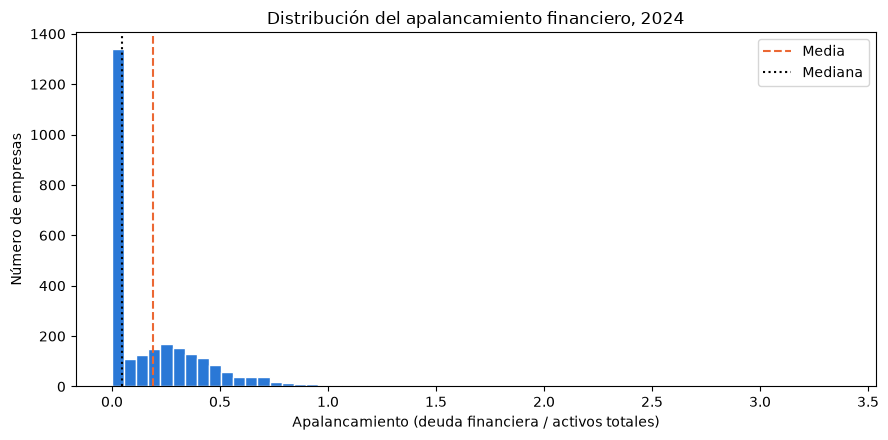

In [14]:
# Crea una figura con un solo panel de 9 x 4.5 pulgadas
fig, ax = plt.subplots(figsize=(9, 4.5))

# Dibuja el histograma: divide Y en 60 rangos y cuenta cuántas empresas caen en cada uno
ax.hist(muestra["apalancamiento_y"], bins=60, color="#2a78d6", edgecolor="white")

# Dibuja una línea vertical punteada en la media
ax.axvline(muestra["apalancamiento_y"].mean(), color="#eb6834", linestyle="--", label="Media")

# Dibuja una línea vertical en la mediana
ax.axvline(muestra["apalancamiento_y"].median(), color="black", linestyle=":", label="Mediana")

# Pone títulos a los ejes y a la gráfica
ax.set_xlabel("Apalancamiento (deuda financiera / activos totales)")
ax.set_ylabel("Número de empresas")
ax.set_title("Distribución del apalancamiento financiero, 2024")

# Muestra la leyenda (qué línea es la media y cuál la mediana)
ax.legend()

# Ajusta márgenes para que nada se corte y muestra la gráfica
plt.tight_layout()
plt.show()

El histograma confirma una distribución sesgada a la derecha ya que hay una barra muy alta en 0 (el 44% de las empresas) y la mayoría de las demás empresas se concentra entre 0 y 0.7 además una cola larga se extiende hacia la derecha hasta 3.37. 

La mediana de 0.05 queda muy cerca del 0 y la media de 0.19 queda más a la derecha porque los valores altos la jalan.

In [15]:
# Agrupa por sector y calcula número de empresas, media y mediana de Y
# Ordena los sectores de menor a mayor mediana
por_sector = muestra.groupby("naics1")["apalancamiento_y"].agg(["count", "mean", "median"]).sort_values("median")

# Muestra la tabla redondeada
por_sector.round(4)

,count,mean,median
naics1,,,
Information,232,0.1773,0.0000
"Professional, Scientific, and Technical Services",150,0.1667,0.0000
Real Estate and Rental and Leasing,68,0.1062,0.0000
Manufacturing,1406,0.1650,0.0119
Construction,49,0.1222,0.0145
Health Care and Social Assistance,65,0.1845,0.0484
Educational Services,12,0.1338,0.0487
Retail Trade,125,0.1904,0.0747
"Mining, Quarrying, and Oil and Gas Extraction",96,0.1791,0.0782


Al agrupar el apalancamiento por sector vemos diferencias claras en el sector de Information, Professional, Scientific and Technical Services y Real Estate la mediana es 0, lo que quiere decir que más de la mitad de sus empresas no tiene deuda financiera.

En el otro extremo Utilities con una mediana de 0.40 y Accommodation and Food Services con mediana de 0.32 son los sectores más endeudados, la empresa típica financia alrededor de un tercio o más de sus activos con deuda financiera.

También vemos sectores con muy pocas empresas, como Educational Services (12), Other Services (14) y Agriculture (14).

/tmp/ipykernel_65297/2191314324.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(datos_por_sector, vert=False)


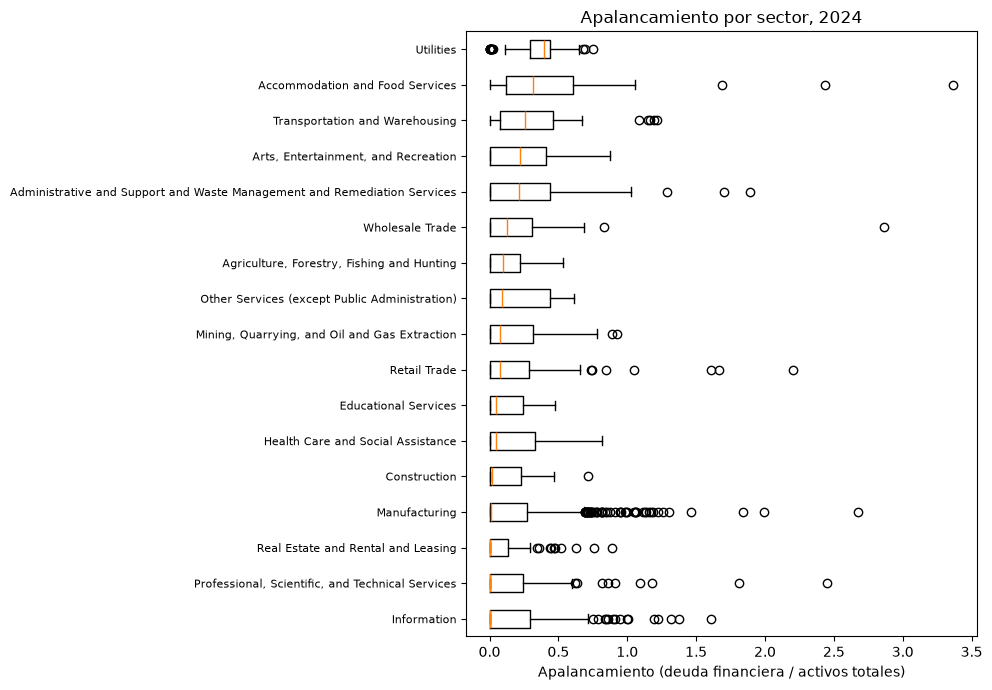

In [16]:
# Lista de sectores en el mismo orden que la tabla (de menor a mayor mediana)
sectores = por_sector.index.tolist()

# Para cada sector, guarda en una lista los valores de Y de sus empresas
datos_por_sector = [muestra.loc[muestra["naics1"] == sector, "apalancamiento_y"] for sector in sectores]

# Crea la figura, más alta porque son muchos sectores
fig, ax = plt.subplots(figsize=(10, 7))

# Dibuja una caja horizontal por sector (vert=False las pone acostadas para que quepan los nombres)
ax.boxplot(datos_por_sector, vert=False)

# Pone el nombre de cada sector junto a su caja
ax.set_yticks(range(1, len(sectores) + 1))
ax.set_yticklabels(sectores, fontsize=8)

# Pone títulos
ax.set_xlabel("Apalancamiento (deuda financiera / activos totales)")
ax.set_title("Apalancamiento por sector, 2024")

plt.tight_layout()
plt.show()

En la gráfica de caja podemos ver como se distribuye el apalancamiento dentro de cada sector donde hay valores aproximados vistos en la gráfica.

Utilities tiene la mediana más alta de aproximadamente 0.40 y una caja angosta que va de 0.30 a 0.45, es decir que sus empresas tienen niveles de deuda parecidos entre sí y sus valores atípicos están en 0 por lo que podemos decir que en este sector lo inusual es no tener deuda, por otro lado Information tiene la mediana en 0 así que más de la mitad de sus empresas no tiene deuda financiera aunque tiene varios valores atípicos a la derecha que llegan hasta aproximadamente 1.6.

Manufacturing también tiene la mediana muy cerca de 0 pero es el sector con más valores atípicos a la derecha y tiene sentido porque es el sector más grande con 1,406 empresas y agrupa empresas muy distintas entre sí.

Finalmente, los valores más alejados donde Y es mayor a 2 aparecen en Accommodation and Food Services (Wingstop y Nathan's Famous), Wholesale Trade (Domino's Pizza), Manufacturing (Bioxcel Therapeutics), Professional, Scientific and Technical Services (SpringBig) y Retail Trade (Rent the Runway) y varios de ellos coinciden con las empresas que tienen la deuda duplicada y puede que su apalancamiento real podría ser menor.

In [17]:
# Columnas a mostrar para revisar cada caso
columnas_ver = ["ticker", "Nombre", "naics1", "totalassets", "shortdebt", "longdebt", "apalancamiento_y"]

# Ordena de mayor a menor apalancamiento y muestra las 10 primeras
muestra.sort_values("apalancamiento_y", ascending=False)[columnas_ver].head(10)

,ticker,Nombre,naics1,totalassets,shortdebt,longdebt,apalancamiento_y
3619,WING,Wingstop Inc,Accommodation and Food Services,716246.0,1206201.0,1206201.0,3.368119
1025,DPZ,Dominos Pizza Inc,Wholesale Trade,1737013.0,1149679.0,3825659.0,2.864307
534,BTAI,"Bioxcel Therapeutics, Inc",Manufacturing,38338.0,0.0,102508.0,2.673796
2948,SBIG,"SpringBig Holdings, Inc.","Professional, Scientific, and Technical Services",6825.0,8364.0,8364.0,2.450989
2290,NATH,"Nathan'S Famous, Inc",Accommodation and Food Services,48858.0,59562.0,59562.0,2.438168
2809,RENT,"Rent The Runway, Inc",Retail Trade,278500.0,306700.0,306700.0,2.202513
507,BRBR,"Bellring Brands, Inc",Manufacturing,837000.0,833100.0,833100.0,1.990681
1183,ETSY,"Etsy, Inc",Administrative and Support and Waste Managemen...,2417782.0,2288083.0,2288083.0,1.892712
3303,TLSI,"TriSalus Life Sciences, Inc.",Manufacturing,23971.0,22084.0,22084.0,1.842560
1015,DOCN,Digitalocean Hldg Inc,"Professional, Scientific, and Technical Services",1639015.0,1485366.0,1485366.0,1.812511


Esta tabla muestra las 10 empresas con mayor apalancamiento y algo curioso es que en varias de ellas como Wingstop, Etsy y DigitalOcean la deuda de corto plazo es exactamente igual a la de largo plazo lo cual es casi imposible, puede ser que la base de datos copió el mismo valor en ambas columnas y esto causó un duplicado de la deuda, en cambio otras empresas como Domino's Pizza con montos distintos y razonables o Bioxcel Therapeutics donde la deuda de largo plazo parecen casos reales de empresas con más deuda que activos. 

Esto lo investigaremos en la siguiente celda de código.

In [18]:
# Empresas cuya deuda de corto plazo es exactamente igual a la de largo plazo, y mayor que cero
deuda_igual = muestra[(muestra["shortdebt"] == muestra["longdebt"]) & (muestra["shortdebt"] > 0)]

# Empresas que tienen ambas deudas mayores a cero (para comparar)
ambas_positivas = ((muestra["shortdebt"] > 0) & (muestra["longdebt"] > 0)).sum()

print("Empresas con ambas deudas mayores a cero:", ambas_positivas)
print("De ellas, con deuda de corto plazo = deuda de largo plazo:", deuda_igual.shape[0])
print("Empresas con deuda igual y Y > 1:", (deuda_igual["apalancamiento_y"] > 1).sum())

# Cuenta empresas por debajo de distintos niveles de activos totales (recuerda: están en miles de dólares)
# f"..." permite insertar variables dentro del texto entre llaves {}
for umbral in [1000, 10000, 50000]:
    n = (muestra["totalassets"] < umbral).sum()
    print(f"Empresas con activos menores a ${umbral / 1000:,.0f} millones: {n}")

Empresas con ambas deudas mayores a cero: 1161
De ellas, con deuda de corto plazo = deuda de largo plazo: 222
Empresas con deuda igual y Y > 1: 32
Empresas con activos menores a $1 millones: 44
Empresas con activos menores a $10 millones: 209
Empresas con activos menores a $50 millones: 475


Confirmamos que de las 1,161 empresas con ambas deudas mayores a cero 222 (el 19%) tienen la deuda de corto plazo igual a la de largo plazo esto no es una coincidencia esto es un error de captura de los datos, además 32 de las 46 empresas con Y mayor a 1 pertenecen a este grupo así que la mayoría de los valores extremos de apalancamiento se deben a la deuda duplicada, por otro lado hay 44 empresas con activos menores a $1 millón, 209 con menos de $10 millones y 475 con menos de $50 millones.

In [19]:
# Columnas para revisar los casos extremos de las X
columnas_x = ["ticker", "Nombre", "totalassets", "rentabilidad_x2", "crecimiento_x4", "depreciacion_x5"]

# Las 10 empresas con rentabilidad más negativa
print(muestra.sort_values("rentabilidad_x2")[columnas_x].head(10).to_string())

# Las 10 empresas con mayor crecimiento
print(muestra.sort_values("crecimiento_x4", ascending=False)[columnas_x].head(10).to_string())

# Las 10 empresas con mayor depreciación sobre activos
print(muestra.sort_values("depreciacion_x5", ascending=False)[columnas_x].head(10).to_string())

     ticker                        Nombre  totalassets  rentabilidad_x2  crecimiento_x4  depreciacion_x5
518    BRQL                  BrooQLy Inc.        0.237     -1370.126582    64848.101266       247.907173
856    CRWE   Crown Equity Holdings, Inc.        3.858      -636.816226     3284.683048       322.582945
1414   GBUX                  GIVBUX, INC.       23.137      -129.784847     5681.641792         0.000000
2966   SCTH  Securetech Innovations, Inc.        3.617      -111.308543     8851.429696         0.271772
2550   OWPC      One World Products, Inc.       68.300       -41.601054       38.296056         0.000000
1459   GLCP           GLOBAL LEADERS CORP        3.540       -17.546045    43614.336158         0.000000
2063   LUDG      LUDWIG ENTERPRISES, INC.      197.556       -15.271032      119.436426         0.000000
2495   ONEI                  OneMeta Inc.      314.847       -14.361468      144.035457         0.000000
3731   ZPTA          Zapata Quantum, Inc.     2733.000 

Al revisar las empresas con valores extremos en las X encontramos un patrón común donde todas tienen activos totales pequeños por ejemplo BrooQLy (BRQL) tiene apenas $237 dólares de activos y por eso su rentabilidad es de -1,370 y su crecimiento de 64,848, otro ejemplo es Crown Equity (CRWE) que tiene $3,858 dólares de activos y una depreciación de 322 veces sus activos, cuando el denominador (activos totales) es tan pequeño cualquier razón financiera pierde sentido económico y estas empresas no representan a las empresas que le interesan a los inversionistas.

#### Decisiones y correcciones

Con base en lo encontrado tomaremos dos decisiones.

Para las 222 empresas con deuda duplicada contaremos la deuda una sola vez, ya que la cifra repetida es un error de captura de la base de datos y contarla dos veces duplicaría su apalancamiento donde 32 de las 46 empresas con Y mayor a 1 tenían este problema, además marcaremos con verdadero o falso si la empresa tenía la deuda duplicada para revisar más adelante si esto afecta o no al modelo.

También excluiremos las 209 empresas con activos totales menores a $10 millones (7.9% de la muestra) porque al tener un denominador tan pequeño sus razones financieras toman valores que no tienen sentido, este filtro no busca eliminar valores extremos en general, ya que los valores extremos de empresas reales se analizarán en el diagnóstico del modelo.

In [20]:
# Umbral mínimo de activos totales, en miles de dólares (10000 = $10 millones)
umbral_activos = 10000

# D7: excluye empresas con activos menores al umbral y lo registra en el mismo embudo del inciso 1b
muestra = aplicar_filtro(muestra, muestra["totalassets"] >= umbral_activos,
                         f"Excluir activos totales menores a ${umbral_activos / 1000:,.0f} millones (denominadores diminutos)",
                         embudo)

# D6: marca las empresas con deuda duplicada (corto plazo igual a largo plazo y mayor que cero)
muestra["deuda_duplicada"] = (muestra["shortdebt"] == muestra["longdebt"]) & (muestra["shortdebt"] > 0)

print("Empresas con deuda duplicada corregida:", muestra["deuda_duplicada"].sum())

# D6: deuda total; si está duplicada se cuenta una sola vez, si no, se suman corto y largo plazo
# np.where(condición, valor si es verdadero, valor si es falso) decide renglón por renglón
deuda_total = np.where(muestra["deuda_duplicada"], muestra["longdebt"], muestra["shortdebt"] + muestra["longdebt"])

# Recalcula Y con la deuda corregida
muestra["apalancamiento_y"] = deuda_total / muestra["totalassets"]

# Muestra el embudo completo y final con todos los filtros
tabla_embudo = pd.DataFrame(embudo)
tabla_embudo

Empresas con deuda duplicada corregida: 221


,Filtro,Eliminadas,Restantes
0,Empresas con datos en 2024 (después del merge),0,3740
1,Excluir sector Finance and Insurance,803,2937
2,Excluir activos totales ≤ 0 (no se puede divid...,3,2934
3,Excluir sin precio o sin número de acciones (n...,225,2709
4,Excluir ingresos o gastos negativos (inconsist...,72,2637
5,Excluir activos totales menores a $10 millones...,209,2428


In [21]:
# Calcula conteo, media, desviación estándar, mínimo, percentiles y máximo de cada variable
# .T voltea la tabla para que cada variable quede en un renglón
descriptiva = muestra[variables_modelo].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

# Redondea a 4 decimales y muestra la tabla
descriptiva.round(4)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
apalancamiento_y,2428.0,0.1760,0.2321,0.0000,0.0000,0.0000,0.0000,0.0810,0.3023,0.5829,0.9121,2.8643
tangibilidad_x1,2428.0,0.1295,0.1884,0.0000,0.0000,0.0000,0.0042,0.0520,0.1667,0.5682,0.8257,0.9795
rentabilidad_x2,2428.0,-0.0488,0.3764,-6.6822,-1.3994,-0.6640,-0.0848,0.0567,0.1188,0.2294,0.3455,2.0312
tamano_x3,2428.0,13.9363,2.2443,9.2162,9.3985,10.1313,12.3295,14.0584,15.5101,17.6022,18.8174,20.2531
crecimiento_x4,2428.0,2.6337,10.0473,0.0002,0.0581,0.1886,0.5447,1.1348,2.4812,7.2946,25.2492,385.1424
depreciacion_x5,2428.0,0.0300,0.0287,0.0000,0.0000,0.0000,0.0102,0.0246,0.0407,0.0787,0.1430,0.2662


In [22]:
# Cuenta empresas sin deuda (Y = 0) y calcula su porcentaje
sin_deuda_muestra = (muestra["apalancamiento_y"] == 0).sum()

print("Empresas con Y = 0:", sin_deuda_muestra, "(", round(sin_deuda_muestra / muestra.shape[0] * 100, 1), "% )")

# Cuenta empresas con más deuda que activos (Y > 1)
mayor_uno = (muestra["apalancamiento_y"] > 1).sum()

print("Empresas con Y > 1:", mayor_uno)

# Cuenta empresas con tangibilidad igual a cero (caso American Airlines)
ceros_tangibilidad = (muestra["tangibilidad_x1"] == 0).sum()

print("Empresas con tangibilidad = 0:", ceros_tangibilidad, "(", round(ceros_tangibilidad / muestra.shape[0] * 100, 1), "% )")

Empresas con Y = 0: 979 ( 40.3 % )
Empresas con Y > 1: 16
Empresas con tangibilidad = 0: 474 ( 19.5 % )


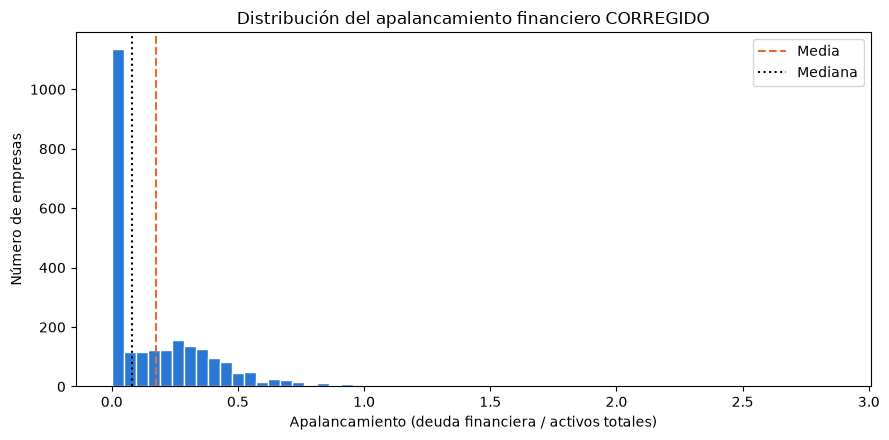

In [23]:
# Crea una figura con un solo panel de 9 x 4.5 pulgadas
fig, ax = plt.subplots(figsize=(9, 4.5))

# Dibuja el histograma: divide Y en 60 rangos y cuenta cuántas empresas caen en cada uno
ax.hist(muestra["apalancamiento_y"], bins=60, color="#2a78d6", edgecolor="white")

# Dibuja una línea vertical punteada en la media
ax.axvline(muestra["apalancamiento_y"].mean(), color="#eb6834", linestyle="--", label="Media")

# Dibuja una línea vertical en la mediana
ax.axvline(muestra["apalancamiento_y"].median(), color="black", linestyle=":", label="Mediana")

# Pone títulos a los ejes y a la gráfica
ax.set_xlabel("Apalancamiento (deuda financiera / activos totales)")
ax.set_ylabel("Número de empresas")
ax.set_title("Distribución del apalancamiento financiero CORREGIDO")

# Muestra la leyenda (qué línea es la media y cuál la mediana)
ax.legend()

# Ajusta márgenes para que nada se corte y muestra la gráfica
plt.tight_layout()
plt.show()

In [24]:
# Agrupa por sector y calcula número de empresas, media y mediana de Y
# Ordena los sectores de menor a mayor mediana
por_sector = muestra.groupby("naics1")["apalancamiento_y"].agg(["count", "mean", "median"]).sort_values("median")

# Muestra la tabla redondeada
por_sector.round(4)

,count,mean,median
naics1,,,
Information,213,0.1585,0.0000
Real Estate and Rental and Leasing,65,0.1021,0.0000
"Professional, Scientific, and Technical Services",128,0.1523,0.0027
Construction,47,0.1189,0.0213
Educational Services,12,0.1004,0.0487
Manufacturing,1273,0.1586,0.0562
Other Services (except Public Administration),14,0.1970,0.0581
"Agriculture, Forestry, Fishing and Hunting",14,0.1319,0.0780
Retail Trade,120,0.1602,0.0843


/tmp/ipykernel_65297/3659439898.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(datos_por_sector, vert=False)


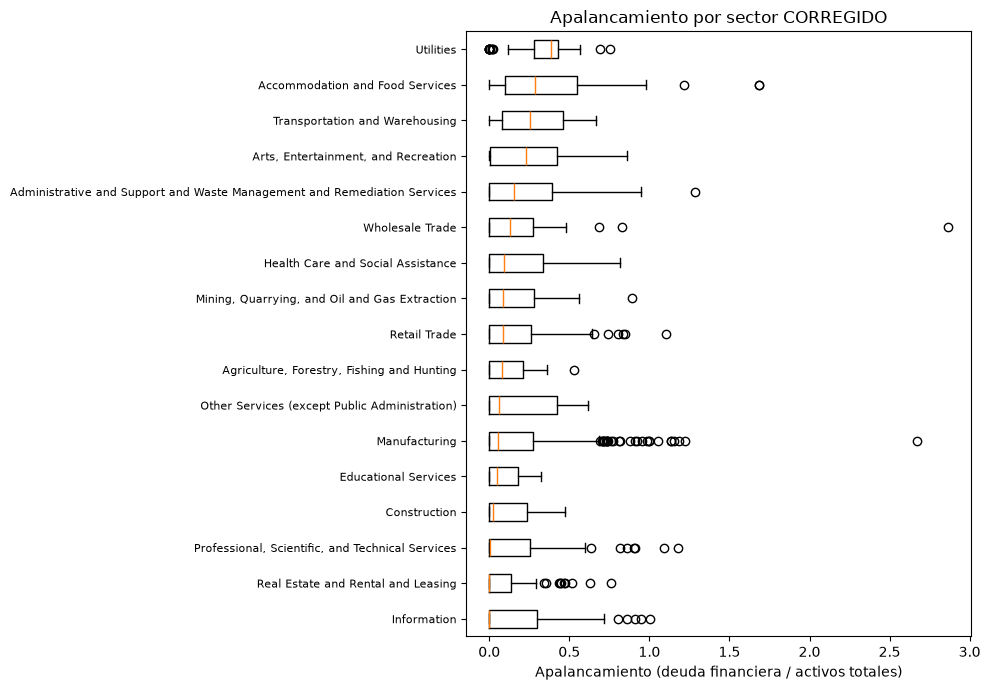

In [25]:
# Lista de sectores en el mismo orden que la tabla (de menor a mayor mediana)
sectores = por_sector.index.tolist()

# Para cada sector, guarda en una lista los valores de Y de sus empresas
datos_por_sector = [muestra.loc[muestra["naics1"] == sector, "apalancamiento_y"] for sector in sectores]

# Crea la figura, más alta porque son muchos sectores
fig, ax = plt.subplots(figsize=(10, 7))

# Dibuja una caja horizontal por sector (vert=False las pone acostadas para que quepan los nombres)
ax.boxplot(datos_por_sector, vert=False)

# Pone el nombre de cada sector junto a su caja
ax.set_yticks(range(1, len(sectores) + 1))
ax.set_yticklabels(sectores, fontsize=8)

# Pone títulos
ax.set_xlabel("Apalancamiento (deuda financiera / activos totales)")
ax.set_title("Apalancamiento por sector CORREGIDO")

plt.tight_layout()
plt.show()

In [26]:
# Columnas a mostrar para revisar cada caso
columnas_ver = ["ticker", "Nombre", "naics1", "totalassets", "shortdebt", "longdebt", "apalancamiento_y"]

# Ordena de mayor a menor apalancamiento y muestra las 10 primeras
muestra.sort_values("apalancamiento_y", ascending=False)[columnas_ver].head(10)

,ticker,Nombre,naics1,totalassets,shortdebt,longdebt,apalancamiento_y
1025,DPZ,Dominos Pizza Inc,Wholesale Trade,1737013.0,1149679.0,3825659.0,2.864307
534,BTAI,"Bioxcel Therapeutics, Inc",Manufacturing,38338.0,0.0,102508.0,2.673796
3710,YUM,"Yum! Brands, Inc",Accommodation and Food Services,6727000.0,27000.0,11306000.0,1.684703
3619,WING,Wingstop Inc,Accommodation and Food Services,716246.0,1206201.0,1206201.0,1.684060
1280,FICO,Fair Isaac Corp,Administrative and Support and Waste Managemen...,1717884.0,15000.0,2194021.0,1.285896
1120,EMBC,Embecta Corp,Manufacturing,1285300.0,9500.0,1565300.0,1.225239
2290,NATH,"Nathan'S Famous, Inc",Accommodation and Food Services,48858.0,59562.0,59562.0,1.219084
169,ALUR,"ALLURION TECHNOLOGIES, INC.",Manufacturing,32813.0,38957.0,0.0,1.187243
629,CCO,Clear Channel Outdoor Hldg Inc,"Professional, Scientific, and Technical Services",4804263.0,348.0,5659957.0,1.178184
2632,PI,Impinj Inc,Manufacturing,489080.0,283493.0,281855.0,1.155942


Haremos una comparación del antes y después de las correcciones.

| Indicador | Antes de corregir | Después de corregir |
|---|---|---|
| Empresas en la muestra | 2,637 | 2,428 |
| Media de Y | 0.1887 | 0.1760 |
| Mediana de Y | 0.0473 | 0.0810 |
| Máximo de Y | 3.3681 | 2.8643 |
| Empresas con Y > 1 | 46 | 16 |
| Empresas con Y = 0 | 1,160 (44.0%) | 979 (40.3%) |
| Rentabilidad mínima | -1,370.13 | -6.68 |
| Crecimiento máximo | 93,345.82 | 385.14 |
| Depreciación máxima | 322.58 | 0.27 |
| Tamaño mínimo (ln) | -1.44 | 9.22 (≈ $10 millones) |
| Empresas con tangibilidad = 0 | 527 (20.0%) | 474 (19.5%) |

Después de las correcciones vemos que la distribución de Y sigue sesgada a la derecha, la media es de 0.176 y es mayor que la mediana de 0.081, ya que la mayoría de las empresas tiene poca o nada de deuda donde el 40.3% tiene Y = 0 y unas pocas tienen mucha. 

Las correcciones que hicimos fueron contar una sola vez la deuda de las 221 empresas que la tenían duplicada y excluir las empresas con activos menores a $10 millones, con lo que el máximo de Y bajó de 3.37 a 2.86 y las empresas con Y mayor a 1 pasaron de 46 a 16.

Aún tenemos valores extremos pero parecen ser reales ya que empresas como Domino's Pizza, Yum! Brands y Wingstop tienen capital contable negativo porque se endeudaron para recomprar acciones o pagar dividendos y otras empresas como Bioxcel Therapeutics son empresas pequeñas con muchas pérdidas acumuladas.

Una limitación de nuestra corrección solo detecta deudas duplicadas exactas, por ejemplo Impinj (PI) tiene una deuda de corto plazo de $283.5 millones y una de largo plazo de $281.9 millones, que podría ser o no otro error de captura.

Por sector vemos diferencias claras como el sector Utilities (con mediana de 0.39), Accommodation and Food Services (0.28) y Transportation and Warehousing (0.25) son los más endeudados mientras que en Information y Real Estate más de la mitad de las empresas no tiene deuda y podemod decir que el sector es importante para explicar el apalancamiento y justifica incluirlo como variable categórica en el modelo tal como señalan Frank y Goyal (2009).

Finalmente nuestras variables X todavía tienen sesgos, por ejemplo el crecimiento tiene una media de 2.63 que es mucho mayor que su mediana de 1.13 y con un máximo de 385 y también la rentabilidad todavía llega a -6.68 más adeltante veremos cómo tratar estos valores en la parte de diagnóstico y posteriormente en la de corrección.

### 1e. Matriz de correlación

In [27]:
# Calcula la correlación de Pearson entre cada par de variables (Y y las X)
matriz_corr = muestra[variables_modelo].corr()

# Muestra la matriz redondeada a 3 decimales
matriz_corr.round(3)

,apalancamiento_y,tangibilidad_x1,rentabilidad_x2,tamano_x3,crecimiento_x4,depreciacion_x5
apalancamiento_y,1.000,0.103,0.157,0.343,-0.059,0.095
tangibilidad_x1,0.103,1.000,0.102,0.155,-0.043,0.269
rentabilidad_x2,0.157,0.102,1.000,0.447,-0.127,0.024
tamano_x3,0.343,0.155,0.447,1.000,-0.132,-0.027
crecimiento_x4,-0.059,-0.043,-0.127,-0.132,1.000,-0.041
depreciacion_x5,0.095,0.269,0.024,-0.027,-0.041,1.000


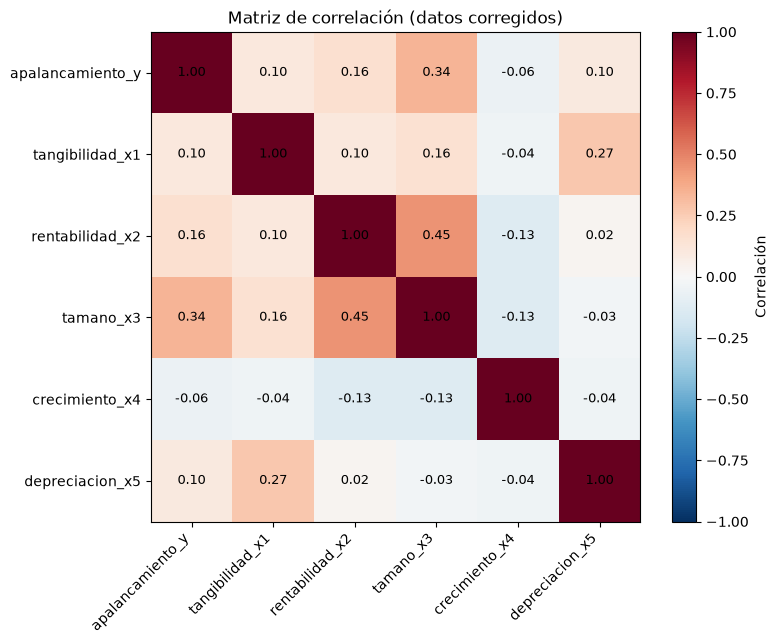

In [28]:
# Crea la figura
fig, ax = plt.subplots(figsize=(8, 6.5))

# Dibuja la matriz como cuadros de color: rojo = positiva, azul = negativa, blanco = cercana a 0
imagen = ax.imshow(matriz_corr, cmap="RdBu_r", vmin=-1, vmax=1)

# Pone los nombres de las variables en ambos ejes (los de abajo inclinados para que quepan)
ax.set_xticks(range(len(variables_modelo)))
ax.set_xticklabels(variables_modelo, rotation=45, ha="right")
ax.set_yticks(range(len(variables_modelo)))
ax.set_yticklabels(variables_modelo)

# Escribe el valor de la correlación dentro de cada cuadro
# .iloc[i, j] toma el valor del renglón i y la columna j
for i in range(len(variables_modelo)):
    for j in range(len(variables_modelo)):
        ax.text(j, i, f"{matriz_corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)

# Agrega la barra que explica qué color corresponde a qué valor
fig.colorbar(imagen, ax=ax, label="Correlación")

ax.set_title("Matriz de correlación (datos corregidos)")
plt.tight_layout()
plt.show()

In [29]:
# Signos esperados que definiste en la Parte 2b
signos_esperados = {"tangibilidad_x1": "+", "rentabilidad_x2": "-", "tamano_x3": "+",
                    "crecimiento_x4": "-", "depreciacion_x5": "-"}

# Arma una tabla con la correlación de cada X con Y junto a su signo esperado
# .drop quita el renglón de Y consigo misma (que siempre vale 1)
comparacion = pd.DataFrame({
    "correlacion_con_y": matriz_corr["apalancamiento_y"].drop("apalancamiento_y"),
    "signo_esperado": pd.Series(signos_esperados)
})

comparacion.round(3)

,correlacion_con_y,signo_esperado
tangibilidad_x1,0.103,+
rentabilidad_x2,0.157,-
tamano_x3,0.343,+
crecimiento_x4,-0.059,-
depreciacion_x5,0.095,-


Al obtener nuestra matriz de correlación vemos que el apalancamiento tiene correlaciones de moderadas a muy débiles con las variables X pot ejemplo con tamaño tenemos la más fuerte que es de 0.34 y es moderada con rentabilidad es de 0.16 y con tangibilidad es de 0.10 las cuales son débiles y con depreciación 0.10 y crecimiento -0.06 que son muy débiles.

Esperábamos un signo positivo para tangibilidad y tamaño y así fue, para crecimiento esperábamos un signo negativo, que también se cumplió, pero con rentabilidad y depreciación salieron con signo positivo cuando esperábamos negativo.

En el caso de la rentabilidad una posible explicación es que está correlacionada con el tamaño (0.45) ya que las empresas grandes tienden a ser más rentables y también a tener más deuda y como la correlación solo compara dos variables a la vez no separa estos efectos más adelante la regresión nos dirá si el signo cambia al controlar por el tamaño.

En el caso de la depreciación está correlacionada con la tangibilidad (0.27) ya que las empresas con más activos físicos deprecian más y también pueden endeudarse más lo cual coincide con lo que encontraron Frank y Goyal (2009) para el apalancamiento contable.

Entre las variables X las correlaciones más altas son entre tamaño y rentabilidad (0.45, moderada) y entre tangibilidad y depreciación (0.27, débil) y ninguna es tan alta como para preocuparnos por multicolinealidad, pero lo revisaremos más adelante.

## Parte 2. Diseño del modelo: hipótesis
### 2a. Revisión de literatura: ¿qué factores se relacionan con el apalancamiento?

**Fuente 1: Rajan y Zingales (1995)**

- **Muestra:** empresas no financieras que cotizan en bolsa en los países del G-7 (Estados Unidos, Japón, Alemania, Francia, Italia, Reino Unido y Canadá) con datos de la base Global Vantage, su análisis principal cubre 1987 a 1991.
- **Exclusión de empresas financieras:** dejan fuera a bancos y aseguradoras porque su apalancamiento está influido por seguros de depósito y regulación y también porque su deuda no es comparable con las deudas de empresas no financieras (Rajan y Zingales, 1995) el cual es el mismo criterio que se aplica en este proyecto.
- **Medida de apalancamiento:** consideran que la deuda de corto y largo plazo entre activos totales es una medida más adecuada que los pasivos totales entre activos ya que los pasivos totales incluyen conceptos como las cuentas por pagar a proveedores que no son financiamiento.
- **Factores estudiados y resultados para Estados Unidos (apalancamiento en libros):**
  - Tangibilidad (activos fijos / activos totales): relación positiva y significativa.
  - Oportunidades de crecimiento (razón valor de mercado a valor en libros): relación negativa y significativa.
  - Tamaño (logaritmo de las ventas): relación positiva y significativa.
  - Rentabilidad (EBITDA / activos totales): relación negativa y significativa.
- **Explicación teórica:**
  - Los activos tangibles sirven como garantía para los acreedores.
  - Las empresas con muchas oportunidades de crecimiento se financian más con acciones ya que una deuda alta las puede llevar a dejar pasar inversiones rentables (Rajan y Zingales, 1995).
  - El efecto del tamaño es ambiguo en teoría: las empresas grandes están más diversificadas y quiebran menos, pero también tienen menos asimetría de información y es más fácil para estos emitir acciones.
  - Para la rentabilidad hay predicciones opuestas: la teoría del orden jerárquico predice una relación negativa (Rajan y Zingales, 1995) en cambio la teoría de agencia de Jensen (Rajan y Zingales, 1995) puede predecir una positiva.

**Fuente 2: Frank y Goyal (2009)**

- **Muestra:** empresas estadounidenses que cotizan en bolsa de 1950 a 2003 con datos de Compustat se excluyen empresas financieras y winsorizan las razones al 0.5% en ambas colas para controlar valores extremos.
- **Medidas de apalancamiento:** analizan cuatro, entre ellas la deuda total entre activos totales en libros (TDA, *total debt to assets*) el cual corresponde exactamente a la razón de este proyecto.
- **Factores principales:** con apalancamiento a valor de mercado seis factores resultan confiables:
  - mediana de apalancamiento de la industria (+),
  - tangibilidad (+),
  - rentabilidad (−),
  - tamaño medido como logaritmo de activos (+),
  - razón valor de mercado a valor en libros (−),
  - inflación esperada (+).
- **Resultado clave para este proyecto:** cuando el apalancamiento se mide en libros solo la mediana de la industria, la tangibilidad y la rentabilidad mantienen un efecto confiable. El tamaño, la razón valor de mercado a valor en libros y la inflación pierden confiabilidad (Frank y Goyal, 2009).
- **Depreciación:** la teoría predice que la depreciación, al ser un escudo fiscal distinto a la deuda este se relaciona negativamente con el apalancamiento (Frank y Goyal, 2009) aunque con apalancamiento en libros los autores encuentran una relación positiva.
- **Teorías que contrastan:** la teoría del equilibrio o trade-off en inglés, la teoría del orden jerárquico o pecking order en inglés y la teoría de sincronización con el mercado o market timing en inglés.

Ambas fuentes estudian empresas no financieras que cotizan en bolsa y miden el apalancamiento de forma muy cercana a la de este proyecto y coinciden en que la tangibilidad y la rentabilidad son los factores más consistentes y además advierten que el efecto del tamaño y de las oportunidades de crecimiento son menos confiables cuando la deuda se mide en libros aún así estos dos factores se incluyen en el modelo y la industria que Frank y Goyal identifican como el factor más importante se incorporará como variable categórica la cual es el sector.

### 2b. Variables del modelo y signos esperados

| Variable | Nombre en el código | Cálculo con columnas del dataset | Signo esperado | Justificación | Fuente |
|---|---|---|---|---|---|
| **Y: Apalancamiento financiero** | `apalancamiento_y` | (shortdebt + longdebt) / totalassets | (variable dependiente) (Nota: Para algunas empresas solo se contó una vez la deuda porque estaban duplicadas las deudas, se explica en el inciso 1d) | Proporción de los activos financiada con deuda financiera | Instrucciones del proyecto |
| **X1: Tangibilidad** | `tangibilidad_x1` | fixedassets / totalassets | + | Los activos físicos (terrenos, edificios, maquinaria) sirven como garantía si la empresa no paga y el acreedor puede recuperarlos como consecuencia le presta más fácilmente | Rajan y Zingales (1995); Frank y Goyal (2009) |
| **X2: Rentabilidad** | `rentabilidad_x2` | (revenue − cogs − sgae) / totalassets | − | Una empresa que genera mucho dinero con su operación puede financiarse con recursos propios y necesita pedir menos prestado (teoría del orden jerárquico) | Rajan y Zingales (1995); Frank y Goyal (2009) |
| **X3: Tamaño** | `tamano_x3` | ln(totalassets) | + | Las empresas grandes tienen más fuentes de ingreso, menor riesgo de quiebra y más reputación, por lo que los acreedores les prestan una proporción mayor de sus activos | Rajan y Zingales (1995); Frank y Goyal (2009) |
| **X4: Oportunidades de crecimiento** | `crecimiento_x4` | (originalprice × sharesoutstanding) / totalassets | − | Si el mercado valora mucho sus acciones a la empresa le conviene financiarse vendiendo acciones en lugar de endeudarse | Rajan y Zingales (1995); Frank y Goyal (2009) |
| **X5: Depreciación** | `depreciacion_x5` | depreciation / totalassets | − | La depreciación ya reduce los impuestos y como el ahorro fiscal tiene un límite entonces el beneficio adicional de los intereses de la deuda es menor | Frank y Goyal (2009) |

**Nota:** la rentabilidad se mide antes de depreciación (EBITDA) como en ambas fuentes esto evita además que la depreciación aparezca en dos variables del modelo.

#### ¿Por qué las variables X no son mecánicas?

Una variable es mecánica si contiene a la Y o a su numerador o denominador de forma que la relación sea casi una identidad contable, la Y de este proyecto tiene en el numerador la deuda financiera (shortdebt + longdebt) que es una parte de los pasivos totales (totalliabilities), por ende podemos decir que si una variable contiene deuda esta variable se convierte en variable mecánica.

- **Criterio general:** De manera general las X seleccionadas están libres de algún dato de deuda.
- **X1 Tangibilidad:** Los activos fijos son algo que la empresa posee y es lo que le deja a los que prestan dinero una garantía tangible en caso de que no pague la empresa y no tiene que ver con la deuda ya que son activos y no pasivos.
- **X2 Rentabilidad:** EBITDA nos da toda la utilidad de la operación antes de los intereses, impuestos, depreciación y amortización, si se usara la utilidad neta no sería lo correcto porque contiene los intereses de la deuda (que es justo lo que hace mecánica la variable si usáramos la utilizad neta).
- **X3 Tamaño:** El tamaño de la empresa influye en el tamaño de la deuda, pero no incluye la deuda como tal, por lo tanto no es mecánica.
- **X4 Crecimiento:** Los papers suman los pasivos al valor del mercado pero yo no los sumo ya que incluyen la deuda y lo que no queremos son variables mecánicas, por lo tanto se excluyen los pasivos y se deja nada más el valor de mercado / activos totales.
- **X5 Depreciación:** La depreciación tiene que ver con qué tanto ahorro de impuestos tiene la empresa sin necesidad de endeudarse y se calcula con el desgaste de los activos fijos, no tiene que ver con la deuda.

### 2c. Hipótesis

#### Hipótesis de la interacción


Espero que el efecto de la rentabilidad sobre el apalancamiento sea distinto según el grupo de tamaño de la empresa ya sea pequeña, mediana o grande. Espero que ante un mismo aumento en la rentabilidad las empresas de mayor tamaño disminuyan su deuda en una medida más grande que una empresa pequeña, esto porque a una empresa de mayor tamaño es más fácil que le presten dinero y casi no vende acciones así que cuando necesita financiamiento externo lo obtiene principalmente con préstamos y cuando genera las suficientes utilidades puede dejar de hacer uso del préstamo y su deuda baja, en cambio en una empresa pequeña las utilidades también pueden reflejar buenas oportunidades de inversión que necesitan dinero así que aunque sea más rentable puede seguir endeudándose. Rajan y Zingales (1995, p. 1457) encontraron este patrón en empresas de Estados Unidos donde el efecto negativo de la rentabilidad sobre el apalancamiento fue más de cuatro veces mayor en las empresas más grandes que en las más pequeñas.

#### Hipótesis del efecto cuadrático

Espero que el efecto de las oportunidades de crecimiento sobre el apalancamiento no sea constante, espero que la relación tenga forma de U invertida donde primero sube y después baja. En empresas con crecimiento bajo espero que al aumentar el crecimiento el apalancamiento suba ligeramente porque a una empresa donde sus acciones no valen mucho los acreedores le tienen poca confianza y le prestan menos y conforme el mercado la valora más puede endeudarse más para cubrir su necesidad financiera y en empresas con crecimiento alto espero que al aumentar el crecimiento el apalancamiento disminuya porque a una empresa donde sus acciones valen mucho le conviene venderlas en vez de endeudarse. Rajan y Zingales (1995, p. 1455, nota 32) encontraron este patrón con una medida parecida a la nuestra que llamaron market-to-book donde la relación con la deuda es ligeramente positiva en las empresas con valores bajos y negativa en las de valores altos además explican el lado alto porque las empresas tienden a vender acciones cuando su precio está alto (p. 1456).

## Parte 3. Estimación del modelo

## Parte 4. Diagnóstico del modelo

## Parte 5. Corrección de problemas y robustez

## Parte 6. Modelo final: desempeño, interpretación y predicciones

## Parte 7. Conclusiones

## Uso de herramientas de IA

## Referencias

Frank, M. Z., y Goyal, V. K. (2009). Capital structure decisions: Which factors are reliably important? *Financial Management, 38*(1), 1–37. https://doi.org/10.1111/j.1755-053X.2009.01026.x

Rajan, R. G., y Zingales, L. (1995). What do we know about capital structure? Some evidence from international data. *The Journal of Finance, 50*(5), 1421–1460. https://www.jstor.org/stable/2329322